## Exercise 1

In [1]:
import numpy as np 
import pandas as pd
import cvxpy as cp
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [2]:
r = 0.01       # Risk-free rate 
mu_m = 0.07    # Expected return of the market portfolio
sigma_m = 0.20 # Market volatility
beta = np.array([-1.00, -0.30, 0.30, 0.60, 1.00, 1.20, 1.50, 2.50])

### Point 1

#### a) Compute the vector µ of expected returns.

In [3]:
mu = r + beta * (mu_m - r) # Compute expected asset returns using the CAPM formula.

for i, m in enumerate(mu, start=1):
    print(f"Asset {i}: {m*100:.2f}%")

Asset 1: -5.00%
Asset 2: -0.80%
Asset 3: 2.80%
Asset 4: 4.60%
Asset 5: 7.00%
Asset 6: 8.20%
Asset 7: 10.00%
Asset 8: 16.00%


#### b) Compute the covariance matrix Σ of stock returns.

In [4]:
sigma_tilde = np.array([0.15, 0.16, 0.10, 0.11, 0.08, 0.13, 0.12, 0.14]) # Idiosyncratic volatilities

Sigma = (sigma_m**2) * np.outer(beta, beta) + np.diag(sigma_tilde**2)    # Compute covariance matrix

np.set_printoptions(formatter={'float': '{:.2%}'.format})
print(Sigma)

[[6.25% 1.20% -1.20% -2.40% -4.00% -4.80% -6.00% -10.00%]
 [1.20% 2.92% -0.36% -0.72% -1.20% -1.44% -1.80% -3.00%]
 [-1.20% -0.36% 1.36% 0.72% 1.20% 1.44% 1.80% 3.00%]
 [-2.40% -0.72% 0.72% 2.65% 2.40% 2.88% 3.60% 6.00%]
 [-4.00% -1.20% 1.20% 2.40% 4.64% 4.80% 6.00% 10.00%]
 [-4.80% -1.44% 1.44% 2.88% 4.80% 7.45% 7.20% 12.00%]
 [-6.00% -1.80% 1.80% 3.60% 6.00% 7.20% 10.44% 15.00%]
 [-10.00% -3.00% 3.00% 6.00% 10.00% 12.00% 15.00% 26.96%]]


#### c) Deduce the vector σ of volatilities and the correlation matrix ρ of stock returns.

In [5]:
sigma = np.sqrt(np.diag(Sigma)) # Compute asset volatilities 

den = np.outer(sigma, sigma)

rho = Sigma / den   # Compute correlation matrix

for i, m in enumerate(sigma, start=1):
    print(f"Asset {i} (Volatility): {m*100:.2f}%")

print("----------------------------------------")
print("Correlation matrix")
print(np.round(rho, 4))

Asset 1 (Volatility): 25.00%
Asset 2 (Volatility): 17.09%
Asset 3 (Volatility): 11.66%
Asset 4 (Volatility): 16.28%
Asset 5 (Volatility): 21.54%
Asset 6 (Volatility): 27.29%
Asset 7 (Volatility): 32.31%
Asset 8 (Volatility): 51.92%
----------------------------------------
Correlation matrix
[[100.00% 28.09% -41.16% -58.97% -74.28% -70.34% -74.28% -77.04%]
 [28.09% 100.00% -18.07% -25.88% -32.60% -30.87% -32.60% -33.81%]
 [-41.16% -18.07% 100.00% 37.93% 47.77% 45.24% 47.77% 49.54%]
 [-58.97% -25.88% 37.93% 100.00% 68.44% 64.82% 68.44% 70.99%]
 [-74.28% -32.60% 47.77% 68.44% 100.00% 81.64% 86.21% 89.41%]
 [-70.34% -30.87% 45.24% 64.82% 81.64% 100.00% 81.64% 84.67%]
 [-74.28% -32.60% 47.77% 68.44% 86.21% 81.64% 100.00% 89.41%]
 [-77.04% -33.81% 49.54% 70.99% 89.41% 84.67% 89.41% 100.00%]]


#### d) Compute the Sharpe ratio of each asset.

In [6]:
SR = (mu - r) / sigma # Sharpe Ratio

for i, s in enumerate(SR, start=1):
    print(f"Asset {i}: SR = {s:.4f}")

Asset 1: SR = -0.2400
Asset 2: SR = -0.1053
Asset 3: SR = 0.1543
Asset 4: SR = 0.2211
Asset 5: SR = 0.2785
Asset 6: SR = 0.2638
Asset 7: SR = 0.2785
Asset 8: SR = 0.2889


#### e) How do you interpret the first two assets #1 and #2? Compute the correlation between asset #1 and the equally-weighted portfolio based on the last six assets. Comment on these results.

In [7]:
w = np.ones(6) / 6 # Define equally-weighted portfolio using assets 3–8

cov_1_p = Sigma[0, 2:8] @ w # Compute covariance between asset 1 and the equally-weighted portfolio

Sigma_sub = Sigma[2:8, 2:8] # Extract covariance matrix of assets 3–8 only

sigma_p = np.sqrt(w @ Sigma_sub @ w) # Compute volatility of the equally-weighted portfolio

rho_1_p = cov_1_p / (sigma[0] * sigma_p) # Compute the correlation between asset 1 and the equally-weighted portfolio

print(f"Correlation asset 1 and Equally-Weighted Assets(3–8): {rho_1_p:.2%}")

Correlation asset 1 and Equally-Weighted Assets(3–8): -78.47%


### Point 2)

#### a) Give the QP formulation of the mean-variance optimization problem:


In [8]:
# REPORT

In [9]:
def solve_gamma(prob, x, gamma_param, g):
    gamma_param.value = float(g)

    # solve the optimization problem using the OSQP solver
    prob.solve(
        solver=cp.OSQP,
        eps_abs=1e-12,
        eps_rel=1e-12,
        max_iter=200000,
        polish=True,
        verbose=False,
        warm_start=True,  
    )

    # check if the solver returned a valid solution
    if x.value is None:
        raise RuntimeError(f"Solver failed for gamma = {g}. Status: {prob.status}")

    x_opt = np.array(x.value).reshape(-1)

    # compute the expected portfolio return
    mu_p = float(mu @ x_opt)

    # compute portfolio variance and standard deviation
    var_p = float(x_opt @ Sigma @ x_opt)
    sigma_p = float(np.sqrt(max(var_p, 0.0)))

    # compute the Sharpe Ratio
    SR = (mu_p - r) / sigma_p if sigma_p > 0 else np.nan

    # compute the total portfolio leverage
    L = float(np.sum(np.abs(x_opt)))

    # return optimal weights and portfolio metrics
    return x_opt, mu_p, sigma_p, SR, L, prob.status

#### b) Using the γ-problem, find the optimal solution x* (γ) when the coefficient γ is equal to 0, 0.10, 0.25, 0.50, 0.75, and 1.00. For each optimized portfolio, compute its expected return µ(x* (γ)), its volatility σ (x* (γ)), its Sharpe ratio SR(x* (γ) | r) and the corresponding leverage ratio L(x*(γ)).

In [10]:
gammas = [0.00, 0.10, 0.25, 0.50, 0.75, 1.00]

# number of assets
n = len(mu)

# portfolio weights variable
x = cp.Variable(n)

# gamma parameter used in the objective
gamma = cp.Parameter()

# vector of ones
ones = np.ones(n)

# vector of excess returns 
excess = mu - r * ones

# mean-variance optimization objective function
objective = cp.Minimize(0.5 * cp.quad_form(x, Sigma) - gamma * (excess @ x))

# portfolio constraints: weights sum to 1 and bounds on positions
costraints = [cp.sum(x) == 1, x >= -10, x <= 10]

# define the optimization problem
prob = cp.Problem(objective, costraints)

rows = []

# solve the optimization problem for each gamma
for g in gammas:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(prob, x, gamma, g)

    row = {"gamma": g}

    # store portfolio weights
    for i, w_i in enumerate(x_opt, start=1):
        row[f"x{i}"] = w_i

    # store portfolio statistics
    row["mu_p"] = mu_p
    row["sigma_p"] = sigma_p
    row["SR"] = SR
    row["L"] = L
    row["status"] = status

    rows.append(row)

df = pd.DataFrame(rows)

fmt = {c: "{:.2%}" for c in df.columns if c not in ["gamma", "SR", "L", "status"]}
fmt.update({"gamma": "{:.2f}", "SR": "{:.4f}", "L": "{:.4f}"})

display(df.style.format(fmt))

,gamma,x1,x2,x3,x4,x5,x6,x7,x8,mu_p,sigma_p,SR,L,status
0,0.00,21.90%,14.29%,25.70%,16.74%,20.32%,5.55%,2.73%,-7.25%,1.27%,5.58%,0.0488,1.1449,optimal
1,0.10,19.18%,12.83%,24.00%,16.18%,21.38%,6.35%,4.38%,-4.30%,2.12%,6.30%,0.1781,1.0861,optimal
2,0.25,15.11%,10.64%,21.45%,15.33%,22.96%,7.55%,6.85%,0.11%,3.39%,9.18%,0.2610,1.0000,optimal
3,0.50,8.31%,6.99%,17.19%,13.92%,25.59%,9.55%,10.97%,7.47%,5.52%,15.60%,0.2895,1.0000,optimal
4,0.75,1.52%,3.34%,12.94%,12.51%,28.23%,11.56%,15.09%,14.83%,7.64%,22.56%,0.2944,1.0000,optimal
5,1.00,-5.28%,-0.32%,8.68%,11.10%,30.86%,13.56%,19.21%,22.18%,9.76%,29.67%,0.2954,1.1119,optimal


#### c) Draw the efficient frontier by considering granular values of γ.

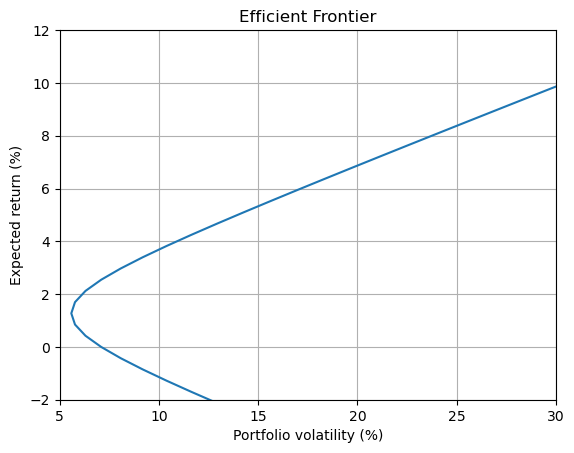

In [11]:
gammas = np.concatenate([
    np.arange(-0.5, 1.05, 0.05),  
    np.arange(2, 11, 1)           
])

# lists to store portfolio returns and volatilities
mu_list = []
sigma_list = []

# solve the optimization problem for each gamma
for g in gammas:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(
        prob, x, gamma, g
    )

    # store results only if the solver found a valid solution
    if status in ["optimal", "optimal_inaccurate"]:
        mu_list.append(mu_p * 100)      
        sigma_list.append(sigma_p * 100)  

# create the efficient frontier plot
plt.figure()
plt.plot(sigma_list, mu_list)

plt.xlabel("Portfolio volatility (%)")
plt.ylabel("Expected return (%)")
plt.title("Efficient Frontier")

# adjust axis limits for better visualization
plt.xlim(5, 30)
plt.ylim(-2, 12)

plt.grid(True)
plt.show()

#### d) Draw the relationship between the risk tolerance γ and the leverage ratio L(x⋆ (γ)) for γ ∈ [−0.5,2.0]. Comment on these results.

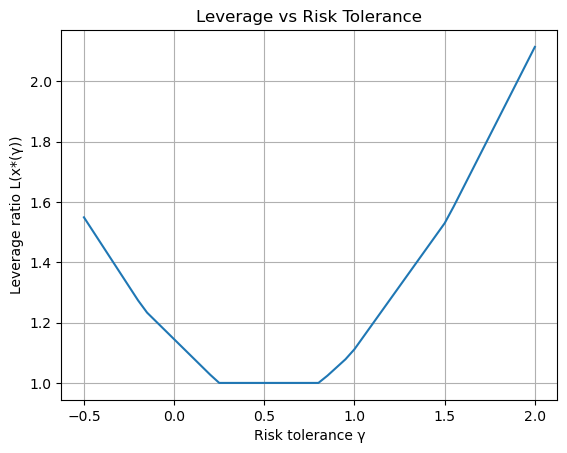

In [12]:
# create a grid of gamma values in the interval [-0.5, 2.0]
gammas = np.arange(-0.5, 2.05, 0.05)

# lists to store leverage values and valid gamma values
leverage_list = []
gamma_valid = []

# solve the optimization problem for each gamma
for g in gammas:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(
        prob, x, gamma, g
    )

    # keep results only if the solver returns a valid solution
    if status in ["optimal", "optimal_inaccurate"]:
        leverage_list.append(L)  
        gamma_valid.append(g)    

# create the leverage vs gamma plot
plt.figure()
plt.plot(gamma_valid, leverage_list)

plt.xlabel("Risk tolerance γ")
plt.ylabel("Leverage ratio L(x*(γ))")
plt.title("Leverage vs Risk Tolerance")

plt.grid(True)
plt.show()

#### e) Using a bisection algorithm, calculate the MVO portfolio if we target an ex-ante volatility of 10% and 15%. Give the corresponding value of γ of the QP problem. For each optimized portfolio, compute its expected return µ(x* (γ)), its volatility σ (x* (γ)) and its Sharpe ratio SR(x* (γ) | r).

In [13]:
def bisection_gamma_target_vol(
    target_sigma,
    prob,
    x,
    gamma_param,
    gamma_low=0.0,
    gamma_high=1.0,
    tol_sigma=1e-6,
    tol_gamma=1e-8,
    max_iter=60,
    max_expand=30
):

    # check feasibility at the lower bound (gamma ≈ minimum-variance portfolio)
    _, _, sigma_low, _, _, status_low = solve_gamma(prob, x, gamma_param, gamma_low)

    # verify that the solver returned a valid solution
    if status_low not in ["optimal", "optimal_inaccurate"]:
        raise RuntimeError(f"Solver failed at gamma_low={gamma_low}. Status: {status_low}")

    # check if the target volatility is feasible
    if sigma_low > target_sigma:
        raise ValueError(
            f"Target volatility {target_sigma:.2%} too low: "
            f"at gamma={gamma_low} you already have sigma={sigma_low:.2%}"
        )

    # compute volatility at the initial upper bound
    _, _, sigma_high, _, _, status_high = solve_gamma(prob, x, gamma_param, gamma_high)

    # verify solver status
    if status_high not in ["optimal", "optimal_inaccurate"]:
        raise RuntimeError(f"Solver failed at gamma_high={gamma_high}. Status: {status_high}")

    expand = 0

    # increase gamma_high until the target volatility is reached
    while sigma_high < target_sigma and expand < max_expand:
        gamma_high *= 2.0
        _, _, sigma_high, _, _, status_high = solve_gamma(prob, x, gamma_param, gamma_high)

        if status_high not in ["optimal", "optimal_inaccurate"]:
            raise RuntimeError(f"Solver failed while expanding gamma_high={gamma_high}. Status: {status_high}")

        expand += 1

    # check if the target volatility is achievable
    if sigma_high < target_sigma:
        raise ValueError(
            f"Target volatility {target_sigma:.2%} too high: "
            f"even at gamma={gamma_high} sigma={sigma_high:.2%} (constraints may bind)"
        )

    # start the bisection search
    gamma_mid = None
    last = None

    for _ in range(max_iter):

        # compute midpoint of the gamma interval
        gamma_mid = 0.5 * (gamma_low + gamma_high)

        # solve the optimization problem at gamma_mid
        x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(
            prob, x, gamma_param, gamma_mid 
        )

        # check solver status
        if status not in ["optimal", "optimal_inaccurate"]:
            raise RuntimeError(f"Solver failed at gamma_mid={gamma_mid}. Status: {status}")

        # store the latest solution
        last = (gamma_mid, x_opt, mu_p, sigma_p, SR, L, status)

        # stop if volatility is close enough to the target or gamma interval is small
        if abs(sigma_p - target_sigma) <= tol_sigma or (gamma_high - gamma_low) <= tol_gamma:
            return last

        # update the bisection interval
        if sigma_p < target_sigma:
            gamma_low = gamma_mid
        else:
            gamma_high = gamma_mid

    # return the last computed solution if max iterations are reached
    return last

In [14]:
# target volatility levels to test
targets = [0.10, 0.15]

# compute the optimal portfolio for each target volatility
for target in targets:

    # find the gamma that produces the target volatility using bisection
    gamma_star, x_star, mu_star, sigma_star, SR_star, L_star, status_star = bisection_gamma_target_vol(
        target_sigma=target,
        prob=prob,
        x=x,
        gamma_param=gamma,
        gamma_low=0.0,
        gamma_high=1.0,
        tol_sigma=1e-6,
        tol_gamma=1e-8,
        max_iter=60
    )

    # print summary of the optimal portfolio
    print("----------------------------------")
    print(f"Target volatility: {target:.0%}")
    print(f"gamma*: {gamma_star:.4f}")
    print(f"mu(x*(gamma*)): {mu_star:.2%}")
    print(f"sigma(x*(gamma*)): {sigma_star:.2%}")
    print(f"Sharpe SR(x*(gamma*) | r): {SR_star:.4f}")
    print(f"Leverage L(x*(gamma*)): {L_star:.4f}")
    print(f"Solver status: {status_star}")

    # print the optimal asset weights
    print("Weights x*(gamma*):")
    for i, w_i in enumerate(x_star, start=1):
        print(f"  x{i}: {w_i:+.2%}")

----------------------------------
Target volatility: 10%
gamma*: 0.2848
mu(x*(gamma*)): 3.69%
sigma(x*(gamma*)): 10.00%
Sharpe SR(x*(gamma*) | r): 0.2690
Leverage L(x*(gamma*)): 1.0000
Solver status: optimal
Weights x*(gamma*):
  x1: +14.16%
  x2: +10.13%
  x3: +20.86%
  x4: +15.14%
  x5: +23.32%
  x6: +7.83%
  x7: +7.43%
  x8: +1.13%
----------------------------------
Target volatility: 15%
gamma*: 0.4778
mu(x*(gamma*)): 5.33%
sigma(x*(gamma*)): 15.00%
Sharpe SR(x*(gamma*) | r): 0.2886
Leverage L(x*(gamma*)): 1.0000
Solver status: optimal
Weights x*(gamma*):
  x1: +8.91%
  x2: +7.31%
  x3: +17.57%
  x4: +14.05%
  x5: +25.36%
  x6: +9.38%
  x7: +10.61%
  x8: +6.82%


#### f) Using the analytical formula, find the tangency portfolio. Compute its expected return µ(x* (γ)), its volatility σ (x* (γ)) and its Sharpe ratio SR(x* (γ) | r). What is the value of the implied risk tolerance associated to the tangency portfolio?

In [15]:
# compute z = Σ^{-1} (μ - r1)
z = np.linalg.solve(Sigma, excess)

# compute the tangency portfolio 
phi0 = ones @ z                  # phi0 = 1^T Σ^{-1} (μ - r1)
x_tan = z / phi0                 

# compute portfolio statistics
mu_tan = float(mu @ x_tan)                     # expected return of the tangency portfolio
var_tan = float(x_tan @ Sigma @ x_tan)         # portfolio variance
sigma_tan = float(np.sqrt(max(var_tan, 0.0)))  # portfolio volatility

# compute Sharpe ratio relative to the risk-free rate
SR_tan = (mu_tan - r) / sigma_tan if sigma_tan > 0 else np.nan

# compute the implied risk tolerance corresponding to the tangency portfolio
gamma_implied = 1.0 / phi0

# print tangency portfolio weights
print("--- Tangency portfolio (analytical) ---")
for i, w in enumerate(x_tan, start=1):
    print(f"x{i}: {w:+.2%}")

# print portfolio performance metrics
print(f"\nmu(x_tan): {mu_tan:.2%}")
print(f"sigma(x_tan): {sigma_tan:.2%}")
print(f"Sharpe | r: {SR_tan:.4f}")

# print implied risk tolerance parameters
print("\n--- Implied risk tolerance ---")
print(f"phi0: {phi0:.4f}")
print(f"gamma_implied: {gamma_implied:.4f}")

--- Tangency portfolio (analytical) ---
x1: -9.21%
x2: -2.43%
x3: +6.22%
x4: +10.28%
x5: +32.39%
x6: +14.72%
x7: +21.59%
x8: +26.44%

mu(x_tan): 10.99%
sigma(x_tan): 33.82%
Sharpe | r: 0.2954

--- Implied risk tolerance ---
phi0: 0.8736
gamma_implied: 1.1447


#### g) Using the efficient frontier with a fine grid of γ, find the tangency portfolio using the brute force algorithm. Compute its expected return µ(x* (γ)), its volatility σ (x* (γ)) and its Sharpe ratio SR(x* (γ) | r).

In [16]:
# create a fine grid of gamma values
gamma_grid = np.linspace(0.0, 5.0, 21500)

# lists to store portfolio statistics and solutions
SR_list = []
mu_list = []
sigma_list = []
L_list = []
x_list = []
gamma_valid = []

# solve the optimization problem for each gamma in the grid
for g in gamma_grid:

    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(
        prob, x, gamma, g
    )

    # store results only if the solution is valid
    if status in ["optimal", "optimal_inaccurate"]:
        SR_list.append(SR)          # Sharpe ratio
        mu_list.append(mu_p)        # expected return
        sigma_list.append(sigma_p)  # portfolio volatility
        L_list.append(L)            # leverage
        x_list.append(x_opt)        # optimal portfolio weights
        gamma_valid.append(g)       # corresponding gamma value

# convert lists into NumPy arrays
SR_arr = np.array(SR_list)
mu_arr = np.array(mu_list)
sigma_arr = np.array(sigma_list)

# find the gamma that maximizes the Sharpe ratio
idx = np.nanargmax(SR_arr)

# extract the portfolio associated with the maximum Sharpe ratio
gamma_star = gamma_valid[idx]
x_star = x_list[idx]
mu_star = mu_arr[idx]
sigma_star = sigma_arr[idx]
SR_star = SR_arr[idx]
L_star = L_list[idx]

# print the brute-force tangency portfolio results
print("\n--- Tangency portfolio (brute force) ---")
print(f"gamma*: {gamma_star:.4f}")
print(f"mu(x*(gamma*)): {mu_star:.2%}")
print(f"sigma(x*(gamma*)): {sigma_star:.2%}")
print(f"Sharpe SR(x*(gamma*) | r): {SR_star:.4f}")
print(f"Leverage L(x*(gamma*)): {L_star:.4f}")

# print the optimal portfolio weights
print("Weights x*(gamma*):")
for i, w_i in enumerate(x_star, start=1):
    print(f"  x{i}: {w_i:+.2%}")


--- Tangency portfolio (brute force) ---
gamma*: 1.1447
mu(x*(gamma*)): 10.99%
sigma(x*(gamma*)): 33.82%
Sharpe SR(x*(gamma*) | r): 0.2954
Leverage L(x*(gamma*)): 1.2329
Weights x*(gamma*):
  x1: -9.21%
  x2: -2.43%
  x3: +6.22%
  x4: +10.28%
  x5: +32.39%
  x6: +14.72%
  x7: +21.59%
  x8: +26.44%


#### h) Now consider the extended quadratic programming problem by including the risk-free asset in the investment universe. Formulate the extended QP problem, and solve it using a fine grid of γ ∈ [0.5,1.5]. What do we observe when calculating the Sharpe ratio of the different optimized portfolios?How can this be explained? Which criterion can be used to implement the brute-force algorithm on the extended QP problem to find the tangency portfolio?

In [17]:
def solve_gamma_extended(prob_ext, x_ext, gamma_param, g):
    gamma_param.value = float(g)

    # solve the extended optimization problem with the OSQP solver
    prob_ext.solve(
        solver=cp.OSQP,
        eps_abs=1e-12,
        eps_rel=1e-12,
        max_iter=200000,
        polish=True,
        verbose=False,
        warm_start=True
    )

    # check whether the solver returned a valid solution
    if x_ext.value is None:
        raise RuntimeError(f"Solver failed for gamma = {g}. Status: {prob_ext.status}")

    x_opt = np.array(x_ext.value).reshape(-1)

    # compute the expected return of the extended portfolio
    mu_p = float(mu_ext @ x_opt)

    # compute portfolio variance and volatility
    var_p = float(x_opt @ Sigma_ext @ x_opt)
    sigma_p = float(np.sqrt(max(var_p, 0.0)))

    # compute the Sharpe ratio
    SR = (mu_p - r) / sigma_p if sigma_p > 0 else np.nan

    # compute total portfolio leverage
    L = float(np.sum(np.abs(x_opt)))

    # return optimal weights and portfolio statistics
    return x_opt, mu_p, sigma_p, SR, L, prob_ext.status


--- Sharpe Ratio statistics (extended problem) ---
Mean Sharpe ratio: 0.2954
Variance Sharpe ratio: 0.0000


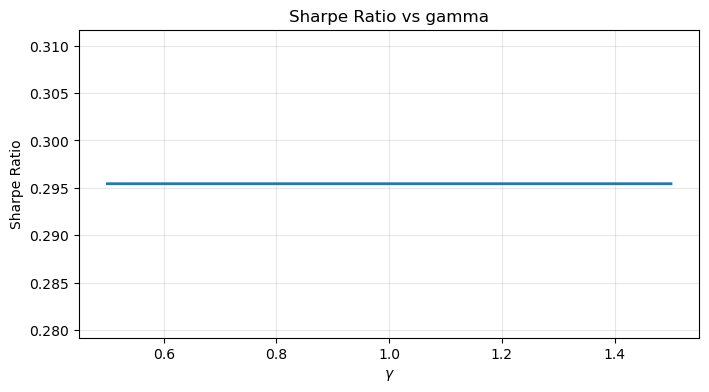


--- Extended QP results (risk-free included) ---


,gamma,x1,x2,x3,x4,x5,x6,x7,x8,x_rf,mu_p,sigma_p,SR,L,status
0,0.5000,-4.02%,-1.06%,2.72%,4.49%,14.15%,6.43%,9.43%,11.55%,56.32%,5.36%,14.77%,0.2954,1.1017,optimal
1,0.5001,-4.02%,-1.06%,2.72%,4.49%,14.15%,6.43%,9.43%,11.55%,56.31%,5.36%,14.77%,0.2954,1.1017,optimal
2,0.5001,-4.03%,-1.06%,2.72%,4.49%,14.15%,6.43%,9.43%,11.55%,56.31%,5.37%,14.78%,0.2954,1.1017,optimal
3,0.5002,-4.03%,-1.06%,2.72%,4.49%,14.15%,6.43%,9.44%,11.55%,56.30%,5.37%,14.78%,0.2954,1.1017,optimal
4,0.5003,-4.03%,-1.06%,2.72%,4.49%,14.16%,6.43%,9.44%,11.56%,56.30%,5.37%,14.78%,0.2954,1.1018,optimal
5,0.5003,-4.03%,-1.06%,2.72%,4.49%,14.16%,6.43%,9.44%,11.56%,56.29%,5.37%,14.78%,0.2954,1.1018,optimal
6,0.5004,-4.03%,-1.06%,2.72%,4.49%,14.16%,6.43%,9.44%,11.56%,56.29%,5.37%,14.78%,0.2954,1.1018,optimal
7,0.5005,-4.03%,-1.06%,2.72%,4.49%,14.16%,6.44%,9.44%,11.56%,56.28%,5.37%,14.79%,0.2954,1.1018,optimal


...



,gamma,x1,x2,x3,x4,x5,x6,x7,x8,x_rf,mu_p,sigma_p,SR,L,status
14992,1.4995,-12.07%,-3.18%,8.15%,13.47%,42.43%,19.28%,28.29%,34.64%,-31.00%,14.09%,44.30%,0.2954,1.9250,optimal
14993,1.4996,-12.07%,-3.18%,8.15%,13.47%,42.43%,19.28%,28.29%,34.64%,-31.00%,14.09%,44.30%,0.2954,1.9251,optimal
14994,1.4997,-12.07%,-3.18%,8.15%,13.47%,42.43%,19.28%,28.29%,34.64%,-31.01%,14.09%,44.31%,0.2954,1.9253,optimal
14995,1.4997,-12.07%,-3.18%,8.15%,13.47%,42.44%,19.28%,28.29%,34.64%,-31.02%,14.09%,44.31%,0.2954,1.9254,optimal
14996,1.4998,-12.07%,-3.18%,8.15%,13.47%,42.44%,19.29%,28.29%,34.64%,-31.02%,14.09%,44.31%,0.2954,1.9255,optimal
14997,1.4999,-12.07%,-3.18%,8.15%,13.47%,42.44%,19.29%,28.29%,34.65%,-31.03%,14.09%,44.31%,0.2954,1.9256,optimal
14998,1.4999,-12.07%,-3.18%,8.15%,13.47%,42.44%,19.29%,28.29%,34.65%,-31.03%,14.09%,44.31%,0.2954,1.9258,optimal
14999,1.5000,-12.07%,-3.18%,8.15%,13.47%,42.44%,19.29%,28.30%,34.65%,-31.04%,14.09%,44.32%,0.2954,1.9259,optimal



--- Tangency portfolio (extended brute force) ---
gamma*: 1.1447
x_rf: -0.00%
mu(x*): 10.99%
sigma(x*): 33.82%
Sharpe | r: 0.2954
Leverage: 1.2329
Risky weights:
  x1: -9.21%
  x2: -2.43%
  x3: +6.22%
  x4: +10.28%
  x5: +32.39%
  x6: +14.72%
  x7: +21.59%
  x8: +26.44%


In [18]:
# extend the asset universe by adding the risk-free asset as the (n+1)-th asset
mu_ext = np.append(mu, r)

# build the extended covariance matrix
Sigma_ext = np.zeros((n + 1, n + 1))
Sigma_ext[:n, :n] = Sigma

# create vectors of ones and excess returns for the extended universe
ones_ext = np.ones(n + 1)
excess_ext = mu_ext - r * ones_ext


# define the same parameterized quadratic program for the extended universe
x_ext = cp.Variable(n + 1)
gamma_ext = cp.Parameter()

# define the mean-variance objective function
objective_ext = cp.Minimize(
    0.5 * cp.quad_form(x_ext, Sigma_ext) - gamma_ext * (excess_ext @ x_ext)
)

# impose the budget constraint and lower/upper bounds on weights
constraints_ext = [cp.sum(x_ext) == 1, x_ext >= -10, x_ext <= 10]

# create the optimization problem
prob_ext = cp.Problem(objective_ext, constraints_ext)

# create a fine grid of gamma values in the interval [0.5, 1.5]
gamma_grid = np.linspace(0.5, 1.5, 15000)

# lists to store results and optimal portfolios
rows = []
x_list = []

# solve the extended optimization problem for each gamma
for g in gamma_grid:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma_extended(
        prob_ext, x_ext, gamma_ext, g
    )

    # skip gamma values for which the solver does not return a valid solution
    if status not in ["optimal", "optimal_inaccurate"]:
        continue

    # store the optimal portfolio weights
    x_list.append(x_opt)

    # store portfolio statistics and risk-free weight in a dictionary
    row = {
        "gamma": g,
        "x_rf": x_opt[-1],      # weight of the risk-free asset
        "mu_p": mu_p,           # expected portfolio return
        "sigma_p": sigma_p,     # portfolio volatility
        "SR": SR,               # Sharpe ratio
        "L": L,                 # leverage
        "status": status
    }

    # add risky asset weights to the result row
    for i, w_i in enumerate(x_opt[:-1], start=1):
        row[f"x{i}"] = w_i

    rows.append(row)

df_ext = pd.DataFrame(rows)

# reorder columns: gamma -> weights -> statistics -> status
weight_cols = [f"x{i}" for i in range(1, n + 1)] + ["x_rf"]
stat_cols = ["mu_p", "sigma_p", "SR", "L"]

df_ext = df_ext[["gamma"] + weight_cols + stat_cols + ["status"]]

# compute mean and variance of the Sharpe ratio
SR_mean_ext = df_ext["SR"].mean()
SR_var_ext = df_ext["SR"].var(ddof=0)  

print("\n--- Sharpe Ratio statistics (extended problem) ---")
print(f"Mean Sharpe ratio: {SR_mean_ext:.4f}")
print(f"Variance Sharpe ratio: {SR_var_ext:.4f}")

# plot the sharpe ratio
plt.figure(figsize=(8, 4))
plt.plot(df_ext["gamma"], df_ext["SR"], lw=2)

plt.xlabel(r"$\gamma$")
plt.ylabel("Sharpe Ratio")
plt.title("Sharpe Ratio vs gamma")
plt.grid(True, alpha=0.3)

plt.show()

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

print("\n--- Extended QP results (risk-free included) ---")

# display the first rows of the results table
display(
    df_ext.head(8).style.format(
        {c: "{:.2%}" for c in df_ext.columns if c not in ["gamma", "SR", "L", "status"]}
        | {"gamma": "{:.4f}", "SR": "{:.4f}", "L": "{:.4f}"}
    )
)

print("...\n")

# display the last rows of the results table 
display(
    df_ext.tail(8).style.format(
        {c: "{:.2%}" for c in df_ext.columns if c not in ["gamma", "SR", "L", "status"]}
        | {"gamma": "{:.4f}", "SR": "{:.4f}", "L": "{:.4f}"}
    )
)

# identify the tangency portfolio in the extended problem, choose the portfolio with risk-free weight closest to zero
idx_tan = np.argmin(np.abs(df_ext["x_rf"].values))

# extract the corresponding gamma and portfolio weights
gamma_tan = float(df_ext.loc[idx_tan, "gamma"])
x_tan_ext = x_list[idx_tan]
x_tan_risky = x_tan_ext[:-1]     # risky asset weights only
x_tan_rf = float(x_tan_ext[-1])  # risk-free asset weight

# print the tangency portfolio statistics
print("\n--- Tangency portfolio (extended brute force) ---")
print(f"gamma*: {gamma_tan:.4f}")
print(f"x_rf: {x_tan_rf:+.2%}")
print(f"mu(x*): {df_ext.loc[idx_tan, 'mu_p']:.2%}")
print(f"sigma(x*): {df_ext.loc[idx_tan, 'sigma_p']:.2%}")
print(f"Sharpe | r: {df_ext.loc[idx_tan, 'SR']:.4f}")
print(f"Leverage: {df_ext.loc[idx_tan, 'L']:.4f}")

# print the risky asset weights of the tangency portfolio
print("Risky weights:")
for i, w_i in enumerate(x_tan_risky, start=1):
    print(f"  x{i}: {w_i:+.2%}")

#### (i) Compare the three solutions (f), (g) and (h) in terms of risk tolerance γ, weights x* (γ), expected return µ(x* (γ)), volatility σ (x* (γ)) and Sharpe ratio SR(x* (γ) | r)

In [19]:
def row_from_weights(method, gamma_val, mu_val, sigma_val, sr_val, w_risky, w_rf=np.nan):
    row = {
        "method": method,
        "gamma": float(gamma_val),
        "mu": float(mu_val),
        "sigma": float(sigma_val),
        "SR": float(sr_val),
        "x_rf": float(w_rf) if not np.isnan(w_rf) else np.nan,
    }
    for i in range(n):
        row[f"x{i+1}"] = float(w_risky[i])
    return row

rows = []

# (f) Analytical tangency (unconstrained)
rows.append(
    row_from_weights(
        method="(f) Analytical",
        gamma_val=gamma_implied,
        mu_val=mu_tan,
        sigma_val=sigma_tan,
        sr_val=SR_tan,
        w_risky=x_tan,
        w_rf=np.nan
    )
)

# (g) Brute-force tangency on efficient frontier (constrained QP)
rows.append(
    row_from_weights(
        method="(g) Brute force",
        gamma_val=gamma_star,
        mu_val=mu_star,
        sigma_val=sigma_star,
        sr_val=SR_star,
        w_risky=x_star,
        w_rf=np.nan
    )
)

# (h) Extended QP with risk-free (take tangency as x_rf ~ 0 solution)
x_rf_h = float(x_tan_ext[-1])
x_risky_h = np.array(x_tan_ext[:-1])

rows.append(
    row_from_weights(
        method="(h) Extended QP",
        gamma_val=gamma_tan,
        mu_val=df_ext.loc[idx_tan, "mu_p"],
        sigma_val=df_ext.loc[idx_tan, "sigma_p"],
        sr_val=df_ext.loc[idx_tan, "SR"],
        w_risky=x_risky_h,
        w_rf=x_rf_h
    )
)

df_compare = pd.DataFrame(rows)

cols = ["method", "gamma"] + [f"x{i}" for i in range(1, n+1)] + ["x_rf", "mu", "sigma", "SR"]
df_compare = df_compare[cols]

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

df_compare.style.format({
    "gamma": "{:.4f}",
    "mu": "{:.2%}",
    "sigma": "{:.2%}",
    "SR": "{:.4f}",
    "x_rf": "{:+.2%}",
    **{f"x{i}": "{:+.2%}" for i in range(1, n+1)}
})

,method,gamma,x1,x2,x3,x4,x5,x6,x7,x8,x_rf,mu,sigma,SR
0,(f) Analytical,1.1447,-9.21%,-2.43%,+6.22%,+10.28%,+32.39%,+14.72%,+21.59%,+26.44%,+nan%,10.99%,33.82%,0.2954
1,(g) Brute force,1.1447,-9.21%,-2.43%,+6.22%,+10.28%,+32.39%,+14.72%,+21.59%,+26.44%,+nan%,10.99%,33.82%,0.2954
2,(h) Extended QP,1.1447,-9.21%,-2.43%,+6.22%,+10.28%,+32.39%,+14.72%,+21.59%,+26.44%,-0.00%,10.99%,33.82%,0.2954


### Point 3)

#### a) We consider the mean-variance optimization problem. We consider the decomposition x = xlong − xshort with xlong ≥ 0 and xshort ≥0. Write the mean-variance optimization problem in terms of x, xlong and xshort.

In [20]:
# REPORT

#### b) Give the augmented QP formulation of the previous mean-variance optimization problem.


In [21]:
def solve_gamma_L1(prob, x_long, x_short, x, gamma_param, g):
    gamma_param.value = float(g)

    # solve the optimization problem using the OSQP solver
    prob.solve(
        solver=cp.OSQP,
        eps_abs=1e-12,
        eps_rel=1e-12,
        max_iter=200000,
        polish=True,
        verbose=False,
        warm_start=True
    )

    # check if the solver returned a valid solution
    if x.value is None:
        raise RuntimeError(f"Solver failed for gamma={g}. Status: {prob.status}")

    x_opt = np.array(x.value).reshape(-1)

    # compute the expected portfolio return
    mu_p = float(mu @ x_opt)

    # compute portfolio variance and volatility
    var_p = float(x_opt @ Sigma @ x_opt)
    sigma_p = float(np.sqrt(max(var_p, 0.0)))

    # compute the Sharpe ratio relative to the risk-free rate
    SR = (mu_p - r) / sigma_p if sigma_p > 0 else np.nan

    # compute the leverage 
    L = float(np.sum(np.array(x_long.value).reshape(-1) + np.array(x_short.value).reshape(-1)))

    # return optimal weights and portfolio statistics
    return x_opt, mu_p, sigma_p, SR, L, prob.status

#### c) Using the γ-problem, find the optimal solution x* (γ) when the coefficient γ is equal to 0, 0.10, 0.25, 0.50, 0.75, and 1.00. For each optimized portfolio, compute its expected return µ(x* (γ)), its volatility σ (x* (γ)), its Sharpe ratio SR(x* (γ) | r) and the corresponding leverage ratio L(x* (γ)).

In [22]:
# define variables for long and short positions
x_long = cp.Variable(n)
x_short = cp.Variable(n)

x = x_long - x_short

# risk tolerance parameter
gamma_L1 = cp.Parameter()

# mean-variance objective function
objective_L1 = cp.Minimize(
    0.5 * cp.quad_form(x, Sigma) - gamma_L1 * (excess @ x)
)

# constraints for the optimization problem
constraints_L1 = [
    cp.sum(x) == 1,                 # portfolio weights must sum to 1
    cp.sum(x_long + x_short) == 1,  # L1 leverage constraint
    x_long >= 0,                    # long positions must be non-negative
    x_short >= 0,                   # short positions must be non-negative
    x >= -10,                       # lower bound on portfolio weights
    x <= 10                         # upper bound on portfolio weights
]

# build the optimization problem once
prob_L1 = cp.Problem(objective_L1, constraints_L1)

# list of gamma values to test
gammas = [0.00, 0.10, 0.25, 0.50, 0.75, 1.00]

# list to store results
rows = []

# solve the optimization problem for each gamma
for g in gammas:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma_L1(
        prob_L1, x_long, x_short, x, gamma_L1, g
    )

    # set very small weights to zero 
    x_opt[np.abs(x_opt) < 1e-10] = 0.0

    # store results for the current gamma
    row = {"gamma": g}

    # store portfolio weights
    for i, w_i in enumerate(x_opt, start=1):
        row[f"x{i}"] = float(w_i)

    # store portfolio statistics
    row["mu_p"] = mu_p
    row["sigma_p"] = sigma_p
    row["SR"] = SR
    row["L"] = L
    row["status"] = status

    rows.append(row)

df_L1 = pd.DataFrame(rows)

cols = ["gamma"] + [f"x{i}" for i in range(1, n + 1)] + ["mu_p", "sigma_p", "SR", "L", "status"]
df_L1 = df_L1[cols]

# show all columns in the output
pd.set_option("display.max_columns", None)

display(
    df_L1.style.format({
        "mu_p": "{:.2%}",
        "sigma_p": "{:.2%}",
        "SR": "{:.4f}",
        "L": "{:.4f}",
        "gamma": "{:.2f}",
        **{f"x{i}": "{:+.2%}" for i in range(1, n+1)}
    })
)

,gamma,x1,x2,x3,x4,x5,x6,x7,x8,mu_p,sigma_p,SR,L,status
0,0.00,+25.03%,+15.60%,+25.92%,+15.63%,+14.93%,+2.89%,+0.00%,+0.00%,1.35%,5.74%,0.0611,1.0000,optimal
1,0.10,+20.91%,+13.57%,+24.20%,+15.64%,+18.57%,+4.95%,+2.15%,+0.00%,2.16%,6.41%,0.1815,1.0000,optimal
2,0.25,+15.11%,+10.64%,+21.45%,+15.33%,+22.96%,+7.55%,+6.85%,+0.11%,3.39%,9.18%,0.2610,1.0000,optimal
3,0.50,+8.31%,+6.99%,+17.19%,+13.92%,+25.59%,+9.55%,+10.97%,+7.47%,5.52%,15.60%,0.2895,1.0000,optimal
4,0.75,+1.52%,+3.34%,+12.94%,+12.51%,+28.23%,+11.56%,+15.09%,+14.83%,7.64%,22.56%,0.2944,1.0000,optimal
5,1.00,+0.00%,+0.00%,+3.86%,+8.37%,+28.87%,+13.41%,+20.08%,+25.41%,9.69%,29.43%,0.2951,1.0000,optimal


#### d) Compare the two solutions 2(b) and 3(c). Comments on these results.


In [23]:
# Rename columns for point 2(b) 
# We rename both weights and portfolio statistics
df_2b = df.rename(columns={
    **{f"x{i}": f"x{i}_2b" for i in range(1, n+1)},
    "mu_p": "mu_2b",
    "sigma_p": "sigma_2b",
    "SR": "SR_2b",
    "L": "L_2b"
})

# Rename columns for point 3(c)
# We rename both weights and portfolio statistics
df_3c = df_L1.rename(columns={
    **{f"x{i}": f"x{i}_3c" for i in range(1, n+1)},
    "mu_p": "mu_3c",
    "sigma_p": "sigma_3c",
    "SR": "SR_3c",
    "L": "L_3c"
})

# Table 1: comparison of portfolio statistics
df_stats = pd.merge(
    df_2b[["gamma", "mu_2b", "sigma_2b", "SR_2b", "L_2b"]],
    df_3c[["gamma", "mu_3c", "sigma_3c", "SR_3c", "L_3c"]],
    on="gamma"
)

display(
    df_stats.style.format({
        "gamma": "{:.2f}",
        "mu_2b": "{:.2%}",
        "sigma_2b": "{:.2%}",
        "SR_2b": "{:.4f}",
        "L_2b": "{:.4f}",
        "mu_3c": "{:.2%}",
        "sigma_3c": "{:.2%}",
        "SR_3c": "{:.4f}",
        "L_3c": "{:.4f}"
    })
)

# Table 2: comparison of portfolio weights 
df_weights = pd.merge(
    df_2b[["gamma"] + [f"x{i}_2b" for i in range(1, n+1)]],
    df_3c[["gamma"] + [f"x{i}_3c" for i in range(1, n+1)]],
    on="gamma"
)

fmt_weights = {
    "gamma": "{:.2f}",
    **{f"x{i}_2b": "{:+.2%}" for i in range(1, n+1)},
    **{f"x{i}_3c": "{:+.2%}" for i in range(1, n+1)}
}

display(df_weights.style.format(fmt_weights))

,gamma,mu_2b,sigma_2b,SR_2b,L_2b,mu_3c,sigma_3c,SR_3c,L_3c
0,0.00,1.27%,5.58%,0.0488,1.1449,1.35%,5.74%,0.0611,1.0000
1,0.10,2.12%,6.30%,0.1781,1.0861,2.16%,6.41%,0.1815,1.0000
2,0.25,3.39%,9.18%,0.2610,1.0000,3.39%,9.18%,0.2610,1.0000
3,0.50,5.52%,15.60%,0.2895,1.0000,5.52%,15.60%,0.2895,1.0000
4,0.75,7.64%,22.56%,0.2944,1.0000,7.64%,22.56%,0.2944,1.0000
5,1.00,9.76%,29.67%,0.2954,1.1119,9.69%,29.43%,0.2951,1.0000


,gamma,x1_2b,x2_2b,x3_2b,x4_2b,x5_2b,x6_2b,x7_2b,x8_2b,x1_3c,x2_3c,x3_3c,x4_3c,x5_3c,x6_3c,x7_3c,x8_3c
0,0.00,+21.90%,+14.29%,+25.70%,+16.74%,+20.32%,+5.55%,+2.73%,-7.25%,+25.03%,+15.60%,+25.92%,+15.63%,+14.93%,+2.89%,+0.00%,+0.00%
1,0.10,+19.18%,+12.83%,+24.00%,+16.18%,+21.38%,+6.35%,+4.38%,-4.30%,+20.91%,+13.57%,+24.20%,+15.64%,+18.57%,+4.95%,+2.15%,+0.00%
2,0.25,+15.11%,+10.64%,+21.45%,+15.33%,+22.96%,+7.55%,+6.85%,+0.11%,+15.11%,+10.64%,+21.45%,+15.33%,+22.96%,+7.55%,+6.85%,+0.11%
3,0.50,+8.31%,+6.99%,+17.19%,+13.92%,+25.59%,+9.55%,+10.97%,+7.47%,+8.31%,+6.99%,+17.19%,+13.92%,+25.59%,+9.55%,+10.97%,+7.47%
4,0.75,+1.52%,+3.34%,+12.94%,+12.51%,+28.23%,+11.56%,+15.09%,+14.83%,+1.52%,+3.34%,+12.94%,+12.51%,+28.23%,+11.56%,+15.09%,+14.83%
5,1.00,-5.28%,-0.32%,+8.68%,+11.10%,+30.86%,+13.56%,+19.21%,+22.18%,+0.00%,+0.00%,+3.86%,+8.37%,+28.87%,+13.41%,+20.08%,+25.41%


### Point 4

#### a) Using the γ-problem, find the optimal solution x*(γ) when the coefficient γ is equal to 0, 0.10, 0.20, 0.50 and 1.00. For each optimized portfolio, compute its expected return µ(x* (γ)), its volatility σ (x* (γ)) and its Sharpe ratio SR(x* (γ) | r). Compare the two solutions 3(c) and 4(a). Comments on these results.

In [24]:
# list of gamma values used in the long-only optimization
gammas_4a = [0.00, 0.10, 0.20, 0.25, 0.50, 1.00]

# number of assets
n = len(mu)

# portfolio weight variable
x = cp.Variable(n)

# gamma parameter used in the objective
gamma = cp.Parameter()

# vector of ones and excess returns
ones = np.ones(n)
excess = mu - r * ones

# mean-variance objective function
objective = cp.Minimize(0.5 * cp.quad_form(x, Sigma) - gamma * (excess @ x))

# long-only constraints: weights must be between 0 and 1 and sum to 1
constraints_longonly = [
    cp.sum(x) == 1,
    x >= 0,
    x <= 1
]

# define the optimization problem
prob_longonly = cp.Problem(objective, constraints_longonly)

# list to store results
rows = []

# solve the optimization problem for each gamma
for g in gammas_4a:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(prob_longonly, x, gamma, g)

    # remove very small numerical values
    x_opt[np.abs(x_opt) < 1e-10] = 0.0

    # create a dictionary for the current result
    row = {"gamma": float(g), "SR": float(SR), "status": status}

    # store portfolio weights
    for i, w_i in enumerate(x_opt, start=1):
        row[f"x{i}"] = float(w_i)

    # store portfolio statistics
    row["mu_p"] = float(mu_p)
    row["sigma_p"] = float(sigma_p)

    rows.append(row)

df_4a = pd.DataFrame(rows)

# reorder columns 
cols = ["gamma"] + [f"x{i}" for i in range(1, n+1)] + ["mu_p", "sigma_p", "SR", "status"]
df_4a = df_4a[cols]

fmt = {c: "{:+.2%}" for c in df_4a.columns if c not in ["gamma", "SR", "status"]}
fmt.update({"gamma": "{:.2f}", "SR": "{:.4f}"})

# display the formatted table
display(df_4a.style.format(fmt))

# compare results with point 3(c)
print("--- Comparison with point 3 (c) ---")

display(
    df_L1.style.format({
        "mu_p": "{:.2%}",
        "sigma_p": "{:.2%}",
        "SR": "{:.4f}",
        "L": "{:.4f}",
        "gamma": "{:.2f}",
        **{f"x{i}": "{:+.2%}" for i in range(1, n+1)}
    })
)

,gamma,x1,x2,x3,x4,x5,x6,x7,x8,mu_p,sigma_p,SR,status
0,0.00,+25.03%,+15.60%,+25.92%,+15.63%,+14.93%,+2.89%,+0.00%,+0.00%,+1.35%,+5.74%,0.0611,optimal
1,0.10,+20.91%,+13.57%,+24.20%,+15.64%,+18.57%,+4.95%,+2.15%,+0.00%,+2.16%,+6.41%,0.1815,optimal
2,0.20,+17.01%,+11.60%,+22.36%,+15.44%,+21.54%,+6.71%,+5.32%,+0.00%,+2.98%,+8.11%,0.2447,optimal
3,0.25,+15.11%,+10.64%,+21.45%,+15.33%,+22.96%,+7.55%,+6.85%,+0.11%,+3.39%,+9.18%,0.2610,optimal
4,0.50,+8.31%,+6.99%,+17.19%,+13.92%,+25.59%,+9.55%,+10.97%,+7.47%,+5.52%,+15.60%,0.2895,optimal
5,1.00,+0.00%,+0.00%,+3.86%,+8.37%,+28.87%,+13.41%,+20.08%,+25.41%,+9.69%,+29.43%,0.2951,optimal


--- Comparison with point 3 (c) ---


,gamma,x1,x2,x3,x4,x5,x6,x7,x8,mu_p,sigma_p,SR,L,status
0,0.00,+25.03%,+15.60%,+25.92%,+15.63%,+14.93%,+2.89%,+0.00%,+0.00%,1.35%,5.74%,0.0611,1.0000,optimal
1,0.10,+20.91%,+13.57%,+24.20%,+15.64%,+18.57%,+4.95%,+2.15%,+0.00%,2.16%,6.41%,0.1815,1.0000,optimal
2,0.25,+15.11%,+10.64%,+21.45%,+15.33%,+22.96%,+7.55%,+6.85%,+0.11%,3.39%,9.18%,0.2610,1.0000,optimal
3,0.50,+8.31%,+6.99%,+17.19%,+13.92%,+25.59%,+9.55%,+10.97%,+7.47%,5.52%,15.60%,0.2895,1.0000,optimal
4,0.75,+1.52%,+3.34%,+12.94%,+12.51%,+28.23%,+11.56%,+15.09%,+14.83%,7.64%,22.56%,0.2944,1.0000,optimal
5,1.00,+0.00%,+0.00%,+3.86%,+8.37%,+28.87%,+13.41%,+20.08%,+25.41%,9.69%,29.43%,0.2951,1.0000,optimal


#### (b) Compare the efficient frontier by considering granular values of γ with the long/short efficient frontier obtained in Question 2.(c). Comment on these results.

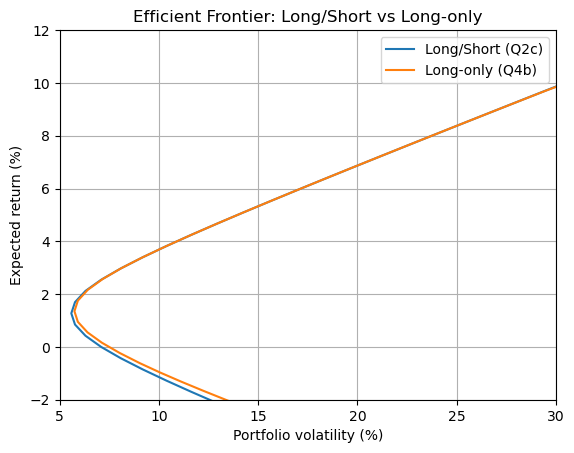

In [25]:
# define the same gamma grid used in question 2(c)
gammas = np.concatenate([
    np.arange(-0.5, 1.05, 0.05),
    np.arange(2, 11, 1)
])

# number of assets, vector of ones, and excess returns
n = len(mu)
ones = np.ones(n)
excess = mu - r * ones

# define the long/short optimization problem from question 2(c)
x_ls = cp.Variable(n)
gamma_ls = cp.Parameter()

objective_ls = cp.Minimize(0.5 * cp.quad_form(x_ls, Sigma) - gamma_ls * (excess @ x_ls))
constraints_ls = [cp.sum(x_ls) == 1, x_ls >= -10, x_ls <= 10]

prob_ls = cp.Problem(objective_ls, constraints_ls)

# lists to store expected returns and volatilities for the long/short case
mu_ls, sig_ls = [], []

# solve the long/short problem for each gamma
for g in gammas:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(prob_ls, x_ls, gamma_ls, g)
    if status in ["optimal", "optimal_inaccurate"]:
        mu_ls.append(mu_p * 100)       
        sig_ls.append(sigma_p * 100)   

# define the long-only optimization problem from question 4(b)
x_lo = cp.Variable(n)
gamma_lo = cp.Parameter()

objective_lo = cp.Minimize(0.5 * cp.quad_form(x_lo, Sigma) - gamma_lo * (excess @ x_lo))
constraints_lo = [cp.sum(x_lo) == 1, x_lo >= 0, x_lo <= 1]

prob_lo = cp.Problem(objective_lo, constraints_lo)

# lists to store expected returns and volatilities for the long-only case
mu_lo, sig_lo = [], []

# solve the long-only problem for each gamma
for g in gammas:
    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(prob_lo, x_lo, gamma_lo, g)
    if status in ["optimal", "optimal_inaccurate"]:
        mu_lo.append(mu_p * 100)       
        sig_lo.append(sigma_p * 100)   

# plot both efficient frontiers on the same graph
plt.figure()
plt.plot(sig_ls, mu_ls, label="Long/Short (Q2c)")
plt.plot(sig_lo, mu_lo, label="Long-only (Q4b)")

plt.xlabel("Portfolio volatility (%)")
plt.ylabel("Expected return (%)")
plt.title("Efficient Frontier: Long/Short vs Long-only")

# set axis limits
plt.xlim(5, 30)
plt.ylim(-2, 12)

plt.grid(True)
plt.legend()
plt.show()

#### c) Using a bisection algorithm, calculate the MVO portfolio if we target an ex-ante volatility of 10% and 20%. Give the corresponding value of γ of the QP problem. For each optimized portfolio, compute its expected return µ(x* (γ)), its volatility σ (x* (γ)) and its Sharpe ratio SR(x*(γ) | r).

In [26]:
n = len(mu)
x_lo = cp.Variable(n)
gamma_lo = cp.Parameter()

# compute the vector of ones and excess returns
ones = np.ones(n)
excess = mu - r * ones

# define the long-only mean-variance objective function
objective_lo = cp.Minimize(0.5 * cp.quad_form(x_lo, Sigma) - gamma_lo * (excess @ x_lo))

# impose long-only constraints: weights sum to 1 and stay between 0 and 1
constraints_lo = [cp.sum(x_lo) == 1, x_lo >= 0, x_lo <= 1]

# create the optimization problem
prob_lo = cp.Problem(objective_lo, constraints_lo)

# target ex-ante volatility levels
targets = [0.10, 0.20]

# list to store results
rows = []

# solve the problem for each target volatility using bisection on gamma
for target_sigma in targets:
    gamma_star_4c, x_opt_4c, mu_p_4c, sigma_p_4c, SR_4c, L_4c, status_4c = bisection_gamma_target_vol(
        target_sigma=target_sigma,
        prob=prob_lo,
        x=x_lo,
        gamma_param=gamma_lo,
        gamma_low=0.0,
        gamma_high=1.0,
        tol_sigma=1e-6,
        tol_gamma=1e-8,
        max_iter=60,
        max_expand=30
    )

    # create a dictionary with the portfolio statistics for the current target volatility
    row = {
        "target_sigma": target_sigma,
        "gamma": gamma_star_4c,
        "mu_p": mu_p_4c,
        "sigma_p": sigma_p_4c,
        "SR": SR_4c,
        "status": status_4c
    }

    # store the optimal portfolio weights
    for i, w_i in enumerate(x_opt_4c, start=1):
        row[f"x{i}"] = w_i

    rows.append(row)

df_4c = pd.DataFrame(rows)

# reorder columns 
cols = ["target_sigma", "gamma"] + [f"x{i}" for i in range(1, n+1)] + ["mu_p", "sigma_p", "SR", "status"]
df_4c = df_4c[cols]

fmt = {c: "{:.2%}" for c in df_4c.columns if c not in ["gamma", "SR", "status"]}
fmt.update({"gamma": "{:.4f}", "SR": "{:.4f}"})

# display the formatted results table
display(df_4c.style.format(fmt))

,target_sigma,gamma,x1,x2,x3,x4,x5,x6,x7,x8,mu_p,sigma_p,SR,status
0,10.00%,0.2848,14.16%,10.13%,20.86%,15.14%,23.32%,7.83%,7.43%,1.13%,3.69%,10.00%,0.2690,optimal
1,20.00%,0.6591,3.99%,4.66%,14.48%,13.02%,27.27%,10.83%,13.59%,12.15%,6.87%,20.00%,0.2934,optimal


#### (d) Find the long-only tangency portfolio x*_MSR. Compute its expected return µ(x*_MSR), its volatility σ(x*_MSR) and its Sharpe ratio SR(x*_MSR | r). Compare these results with those obtained in the long/short case.

In [27]:
n = len(mu)
ones = np.ones(n)
excess = mu - r * ones

x_lo = cp.Variable(n)
gamma_lo = cp.Parameter()

# define the long-only mean-variance objective function
objective_lo = cp.Minimize(
    0.5 * cp.quad_form(x_lo, Sigma) - gamma_lo * (excess @ x_lo)
)

# impose long-only constraints
constraints_lo = [cp.sum(x_lo) == 1, x_lo >= 0, x_lo <= 1]

# create the optimization problem
prob_lo = cp.Problem(objective_lo, constraints_lo)

# create a fine grid of gamma values, as in point 2g
gamma_grid_lo = np.linspace(0.0, 5, 5001)

# lists to store portfolio statistics and solutions
SR_list_lo = []
mu_list_lo = []
sigma_list_lo = []
L_list_lo = []
x_list_lo = []
gamma_valid_lo = []

# solve the optimization problem for each gamma in the grid
for g in gamma_grid_lo:

    x_opt, mu_p, sigma_p, SR, L, status = solve_gamma(
        prob_lo, x_lo, gamma_lo, g
    )

    # store results only if the solution is valid
    if status in ["optimal", "optimal_inaccurate"] and np.isfinite(SR):
        SR_list_lo.append(SR)          # Sharpe ratio
        mu_list_lo.append(mu_p)        # expected return
        sigma_list_lo.append(sigma_p)  # portfolio volatility
        L_list_lo.append(L)            # leverage
        x_list_lo.append(x_opt)        # optimal portfolio weights
        gamma_valid_lo.append(g)       # corresponding gamma value

# convert lists into NumPy arrays
SR_arr_lo = np.array(SR_list_lo)
mu_arr_lo = np.array(mu_list_lo)
sigma_arr_lo = np.array(sigma_list_lo)

# find the gamma that maximizes the Sharpe ratio
idx_lo = int(np.nanargmax(SR_arr_lo))

# extract the portfolio associated with the maximum Sharpe ratio
gamma_msr_lo = float(gamma_valid_lo[idx_lo])
x_msr_lo = np.array(x_list_lo[idx_lo]).copy()
mu_msr_lo = float(mu_arr_lo[idx_lo])
sig_msr_lo = float(sigma_arr_lo[idx_lo])
SR_msr_lo = float(SR_arr_lo[idx_lo])
L_msr_lo = float(L_list_lo[idx_lo])

# remove very small numerical values
x_msr_lo[np.abs(x_msr_lo) < 1e-10] = 0.0

# create a comparison table including previous long/short and long-only cases
rows = []

def row_full(case, gamma_val, mu_val, sigma_val, sr_val, w_risky, L_val, x_rf_val=np.nan):
    row = {
        "case": case,
        "gamma": float(gamma_val),
        "mu": float(mu_val),
        "sigma": float(sigma_val),
        "SR": float(sr_val),
        "L": float(L_val),
        "x_rf": float(x_rf_val) if not np.isnan(x_rf_val) else np.nan
    }

    # store risky asset weights
    for i in range(n):
        row[f"x{i+1}"] = float(w_risky[i])

    return row


# add the analytical long/short tangency portfolio
rows.append(
    row_full(
        "LS analytical",
        gamma_implied,
        mu_tan,
        sigma_tan,
        SR_tan,
        x_tan,
        np.sum(np.abs(x_tan)),
        np.nan
    )
)

# add the brute-force long/short tangency portfolio
rows.append(
    row_full(
        "LS brute force",
        gamma_star,
        mu_star,
        sigma_star,
        SR_star,
        x_star,
        L_star,
        np.nan
    )
)

# add the extended problem solution including the risk-free asset
x_rf_h = float(x_tan_ext[-1])
x_risky_h = np.array(x_tan_ext[:-1])

rows.append(
    row_full(
        "Extended (rf)",
        gamma_tan,
        float(df_ext.loc[idx_tan, "mu_p"]),
        float(df_ext.loc[idx_tan, "sigma_p"]),
        float(df_ext.loc[idx_tan, "SR"]),
        x_risky_h,
        float(df_ext.loc[idx_tan, "L"]),
        x_rf_h
    )
)

# add the long-only maximum Sharpe ratio portfolio
rows.append(
    row_full(
        "Long-only MSR",
        gamma_msr_lo,
        mu_msr_lo,
        sig_msr_lo,
        SR_msr_lo,
        x_msr_lo,
        L_msr_lo,
        np.nan
    )
)

df_final = pd.DataFrame(rows)

# reorder columns 
cols = (
    ["case", "gamma"]
    + [f"x{i}" for i in range(1, n+1)]
    + ["x_rf", "mu", "sigma", "SR", "L"]
)

df_final = df_final[cols]

display(
    df_final.style.format({
        "gamma": "{:.4f}",
        "mu": "{:.2%}",
        "sigma": "{:.2%}",
        "SR": "{:.4f}",
        "L": "{:.4f}",
        "x_rf": "{:+.2%}",
        **{f"x{i}": "{:+.2%}" for i in range(1, n+1)}
    })
)

,case,gamma,x1,x2,x3,x4,x5,x6,x7,x8,x_rf,mu,sigma,SR,L
0,LS analytical,1.1447,-9.21%,-2.43%,+6.22%,+10.28%,+32.39%,+14.72%,+21.59%,+26.44%,+nan%,10.99%,33.82%,0.2954,1.2329
1,LS brute force,1.1447,-9.21%,-2.43%,+6.22%,+10.28%,+32.39%,+14.72%,+21.59%,+26.44%,+nan%,10.99%,33.82%,0.2954,1.2329
2,Extended (rf),1.1447,-9.21%,-2.43%,+6.22%,+10.28%,+32.39%,+14.72%,+21.59%,+26.44%,-0.00%,10.99%,33.82%,0.2954,1.2329
3,Long-only MSR,0.9660,+0.00%,+0.00%,+5.57%,+9.21%,+29.01%,+13.18%,+19.34%,+23.69%,+nan%,9.42%,28.51%,0.2952,1.0000


#### (e) Compute the beta coefficient βi of each asset with respect to the long-only tangency portfolio x*_MSR. Deduce the implied expected return µi that is priced in by the market, and the corresponding alpha coefficient α_i of each asset.

In [28]:
x_m = np.array(x_msr_lo).reshape(-1)

# compute market portfolio expected return and variance
mu_m = float(mu @ x_m)
var_m = float(x_m @ Sigma @ x_m)

# check that market variance is strictly positive
if var_m <= 0:
    raise ValueError(f"Non-positive market variance: {var_m}")

# compute covariance between each asset and the market portfolio
cov_im = Sigma @ x_m

# compute CAPM beta for each asset
beta = cov_im / var_m

# compute CAPM-implied expected return for each asset
mu_capm = r + beta * (mu_m - r)

# compute alpha as the difference between actual and CAPM-implied return
alpha = mu - mu_capm

# create a DataFrame with asset names and CAPM statistics
df_e = pd.DataFrame({
    "asset": [f"Asset {i+1}" for i in range(len(mu))],
    "beta": beta,
    "mu_i": mu,
    "mu_capm": mu_capm,
    "alpha": alpha
})

# define formatting rules for the output table
fmt = {
    "beta": "{:.4f}",
    "mu_i": "{:.2%}",
    "mu_capm": "{:.2%}",
    "alpha": "{:+.2%}",
}

# display the formatted table
display(df_e.style.format(fmt))

,asset,beta,mu_i,mu_capm,alpha
0,Asset 1,-0.6901,-5.00%,-4.81%,-0.19%
1,Asset 2,-0.2070,-0.80%,-0.74%,-0.06%
2,Asset 3,0.2139,2.80%,2.80%,+0.00%
3,Asset 4,0.4278,4.60%,4.60%,+0.00%
4,Asset 5,0.7130,7.00%,7.00%,+0.00%
5,Asset 6,0.8556,8.20%,8.20%,+0.00%
6,Asset 7,1.0695,10.00%,10.00%,-0.00%
7,Asset 8,1.7824,16.00%,16.00%,-0.00%


### Point 5)

In [29]:
def risk_decomposition(x, Sigma):
    x = np.asarray(x, dtype=float).reshape(-1)

    # compute portfolio volatility
    sigma_p = float(np.sqrt(x @ Sigma @ x))

    # compute marginal risk contributions 
    MR = (Sigma @ x) / sigma_p

    # compute risk contributions of each asset
    RC = x * MR

    # compute relative risk contributions 
    RRC = RC / sigma_p

    # return portfolio volatility and risk contribution measures
    return sigma_p, MR, RC, RRC

#### a) Give the risk decomposition of the long-only tangency portfolio x*_MSR (MSR)

In [30]:
# compute the risk decomposition for the MSR portfolio
sigma_msr, MR_msr, RC_msr, RRC_msr = risk_decomposition(x_msr_lo, Sigma)

assets = list(range(1, len(x_msr_lo)+1))

# build a DataFrame with portfolio weights and risk contributions
df_msr = pd.DataFrame({
    "Asset": assets,
    "x_i": x_msr_lo,     # portfolio weight of each asset
    "MR_i": MR_msr,      # marginal risk contribution
    "RC_i": RC_msr,      # risk contribution
    "RC_i*": RRC_msr     # relative risk contribution 
})

df_msr.loc[len(df_msr)] = ["R(x)", np.nan, np.nan, sigma_msr, np.nan]

# display the formatted risk decomposition table
display(
    df_msr.style.format({
        "x_i": "{:.2%}",
        "MR_i": "{:.2%}",
        "RC_i": "{:.2%}",
        "RC_i*": "{:.2%}"
    }, na_rep="")
)

# print checks for the decomposition consistency
print("Portfolio volatility:", f"{sigma_msr:.2%}")
print("Sum RC:", f"{RC_msr.sum():.2%}")
print("Sum RRC:", f"{RRC_msr.sum():.2%}")

,Asset,x_i,MR_i,RC_i,RC_i*
0,1,0.00%,-19.68%,-0.00%,-0.00%
1,2,0.00%,-5.90%,-0.00%,-0.00%
2,3,5.57%,6.10%,0.34%,1.19%
3,4,9.21%,12.20%,1.12%,3.94%
4,5,29.01%,20.33%,5.90%,20.69%
5,6,13.18%,24.39%,3.22%,11.28%
6,7,19.34%,30.49%,5.90%,20.69%
7,8,23.69%,50.82%,12.04%,42.22%
8,R(x),,,28.51%,


Portfolio volatility: 28.51%
Sum RC: 28.51%
Sum RRC: 100.00%


#### b) Give the risk decomposition of the equally-weighted portfolio (EW).

In [31]:
# define the equally weighted (EW) portfolio
n = len(mu)
x_ew = np.ones(n) / n   # each asset receives the same weight

# compute the risk decomposition of the EW portfolio
sigma_ew, MR_ew, RC_ew, RRC_ew = risk_decomposition(x_ew, Sigma)

assets = list(range(1, len(x_ew)+1))

# build a DataFrame containing weights and risk contribution measures
df_ew = pd.DataFrame({
    "Asset": assets,
    "x_i": x_ew,     # portfolio weight of each asset
    "MR_i": MR_ew,   # marginal risk contribution
    "RC_i": RC_ew,   # risk contribution
    "RC_i*": RRC_ew  # relative risk contribution 
})

df_ew.loc[len(df_ew)] = ["R(x)", np.nan, np.nan, sigma_ew, np.nan]

# display the formatted table with percentages
display(
    df_ew.style.format({
        "x_i": "{:.2%}",
        "MR_i": "{:.2%}",
        "RC_i": "{:.2%}",
        "RC_i*": "{:.2%}"
    }, na_rep="")
)

# print consistency checks for the risk decomposition
print("Portfolio volatility:", f"{sigma_ew:.2%}")
print("Sum RC:", f"{RC_ew.sum():.2%}")
print("Sum RRC:", f"{RRC_ew.sum():.2%}")

,Asset,x_i,MR_i,RC_i,RC_i*
0,1,12.50%,-17.26%,-2.16%,-14.22%
1,2,12.50%,-3.63%,-0.45%,-2.99%
2,3,12.50%,6.56%,0.82%,5.40%
3,4,12.50%,12.47%,1.56%,10.27%
4,5,12.50%,19.64%,2.46%,16.18%
5,6,12.50%,24.33%,3.04%,20.05%
6,7,12.50%,29.86%,3.73%,24.60%
7,8,12.50%,49.40%,6.18%,40.70%
8,R(x),,,15.17%,


Portfolio volatility: 15.17%
Sum RC: 15.17%
Sum RRC: 100.00%


#### c) Give the risk decomposition of the long-only minimum variance portfolio (MV).

In [32]:
# compute the minimum variance portfolio by setting gamma = 0
x_mv, mu_mv, sigma_mv, SR_mv, L_mv, status_mv = solve_gamma(prob_lo, x_lo, gamma_lo, 0.0)

# remove very small numerical values in the weights
x_mv[np.abs(x_mv) < 1e-10] = 0.0

# compute the risk decomposition of the minimum variance portfolio
sigma_mv, MR_mv, RC_mv, RRC_mv = risk_decomposition(x_mv, Sigma)

assets = list(range(1, len(x_mv)+1))

# build a DataFrame with weights and risk contribution measures
df_mv = pd.DataFrame({
    "Asset": assets,
    "x_i": x_mv,     # portfolio weight of each asset
    "MR_i": MR_mv,   # marginal risk contribution
    "RC_i": RC_mv,   # risk contribution
    "RC_i*": RRC_mv  # relative risk contribution 
})

df_mv.loc[len(df_mv)] = ["R(x)", np.nan, np.nan, sigma_mv, np.nan]

# display the formatted risk decomposition table
display(
    df_mv.style.format({
        "x_i": "{:.2%}",
        "MR_i": "{:.2%}",
        "RC_i": "{:.2%}",
        "RC_i*": "{:.2%}"
    }, na_rep="")
)

# print consistency checks for the decomposition
print("Portfolio volatility:", f"{sigma_mv:.2%}")
print("Sum RC:", f"{RC_mv.sum():.2%}")
print("Sum RRC:", f"{RRC_mv.sum():.2%}")

,Asset,x_i,MR_i,RC_i,RC_i*
0,1,25.03%,5.74%,1.44%,25.03%
1,2,15.60%,5.74%,0.90%,15.60%
2,3,25.92%,5.74%,1.49%,25.92%
3,4,15.63%,5.74%,0.90%,15.63%
4,5,14.93%,5.74%,0.86%,14.93%
5,6,2.89%,5.74%,0.17%,2.89%
6,7,0.00%,6.11%,0.00%,0.00%
7,8,0.00%,10.18%,0.00%,0.00%
8,R(x),,,5.74%,


Portfolio volatility: 5.74%
Sum RC: 5.74%
Sum RRC: 100.00%


#### d) Give the risk decomposition of the long-only most diversified portfolio (MDP).

In [33]:
# compute the vector of individual asset volatilities
sigma_assets = np.sqrt(np.diag(Sigma))

# define the logarithm of the diversification ratio
def log_diversification_ratio(x, Sigma, sigma_assets):
    num = x @ sigma_assets                # weighted average of individual asset volatilities
    den = np.sqrt(x @ Sigma @ x)          # portfolio volatility
    return np.log(num / den)              # log diversification ratio

# define the objective function to minimize
def neg_log_DR(x, Sigma, sigma_assets):
    return -log_diversification_ratio(x, Sigma, sigma_assets)

# define the portfolio constraints
cons = [{"type": "eq", "fun": lambda x: np.sum(x) - 1}]
bounds = [(0, 1)] * len(mu)

# solve the most diversified portfolio problem using SLSQP
res = minimize(
    neg_log_DR,
    np.ones(len(mu)) / len(mu),           
    args=(Sigma, sigma_assets),
    method="SLSQP",
    bounds=bounds,
    constraints=cons
)

# extract the optimal most diversified portfolio weights
x_mdp = res.x

# compute the risk decomposition of the most diversified portfolio
sigma_mdp, MR_mdp, RC_mdp, RRC_mdp = risk_decomposition(x_mdp, Sigma)

assets = list(range(1, len(x_mdp) + 1))

# build a DataFrame with weights and risk contribution measures
df_mdp = pd.DataFrame({
    "Asset": assets,
    "x_i": x_mdp,      # portfolio weight of each asset
    "MR_i": MR_mdp,    # marginal risk contribution
    "RC_i": RC_mdp,    # risk contribution
    "RC_i*": RRC_mdp   # relative risk contribution 
})

df_mdp.loc[len(df_mdp)] = ["R(x)", np.nan, np.nan, sigma_mdp, np.nan]

# display the formatted risk decomposition table
display(
    df_mdp.style.format({
        "x_i": "{:.2%}",
        "MR_i": "{:.2%}",
        "RC_i": "{:.2%}",
        "RC_i*": "{:.2%}"
    }, na_rep="")
)

# print consistency checks for the decomposition
print("Portfolio volatility:", f"{sigma_mdp:.2%}")
print("Sum RC:", f"{RC_mdp.sum():.2%}")
print("Sum RRC:", f"{RRC_mdp.sum():.2%}")

,Asset,x_i,MR_i,RC_i,RC_i*
0,1,35.96%,7.08%,2.55%,38.58%
1,2,16.49%,4.84%,0.80%,12.09%
2,3,11.55%,3.30%,0.38%,5.78%
3,4,8.22%,4.61%,0.38%,5.74%
4,5,9.53%,6.10%,0.58%,8.80%
5,6,5.94%,7.73%,0.46%,6.95%
6,7,6.36%,9.15%,0.58%,8.81%
7,8,5.95%,14.70%,0.87%,13.24%
8,R(x),,,6.60%,


Portfolio volatility: 6.60%
Sum RC: 6.60%
Sum RRC: 100.00%


#### e) Compute the equal risk contribution portfolio using the CCD algorithm. Give its risk decomposition

In [34]:
# compute individual asset volatilities
sigma_assets = np.sqrt(np.diag(Sigma))

# compute the correlation matrix from the covariance matrix
rho = Sigma / np.outer(sigma_assets, sigma_assets)

def erc_ccd(sigma_assets, rho, lam=1.0, tol=1e-12, max_iter=10000):

    n = len(sigma_assets)

    y = np.ones(n)

    # iterate until convergence or maximum number of iterations
    for k in range(max_iter):

        y_old = y.copy()

        for i in range(n):

            beta_i = sigma_assets[i] * (
                np.dot(rho[i, :i] * sigma_assets[:i], y[:i]) +
                np.dot(rho[i, i+1:] * sigma_assets[i+1:], y_old[i+1:])
            )

            alpha_i = sigma_assets[i]**2
            gamma_i = -lam

            y[i] = (-beta_i + np.sqrt(beta_i**2 - 4 * alpha_i * gamma_i)) / (2 * alpha_i)

        # stop if the largest coordinate update is below tolerance
        if np.max(np.abs(y - y_old)) < tol:
            break

    x = y / y.sum()

    return x


# compute the equal risk contribution portfolio
x_erc = erc_ccd(sigma_assets, rho)

# compute the risk decomposition of the ERC portfolio
sigma_erc, MR_erc, RC_erc, RRC_erc = risk_decomposition(x_erc, Sigma)

assets = list(range(1, len(x_erc) + 1))

# build a DataFrame with portfolio weights and risk contribution measures
df_erc = pd.DataFrame({
    "Asset": assets,
    "x_i": x_erc,      # portfolio weight of each asset
    "MR_i": MR_erc,    # marginal risk contribution
    "RC_i": RC_erc,    # risk contribution
    "RC_i*": RRC_erc   # relative risk contribution 
})

df_erc.loc[len(df_erc)] = ["R(x)", np.nan, np.nan, sigma_erc, np.nan]

# display the formatted risk decomposition table
display(
    df_erc.style.format({
        "x_i": "{:.2%}",
        "MR_i": "{:.2%}",
        "RC_i": "{:.2%}",
        "RC_i*": "{:.2%}"
    }, na_rep="")
)

# print consistency checks for the decomposition
print("Portfolio volatility:", f"{sigma_erc:.2%}")
print("Sum RC:", f"{RC_erc.sum():.2%}")
print("Sum RRC:", f"{RRC_erc.sum():.2%}")

,Asset,x_i,MR_i,RC_i,RC_i*
0,1,29.69%,2.66%,0.79%,12.50%
1,2,17.20%,4.59%,0.79%,12.50%
2,3,16.07%,4.92%,0.79%,12.50%
3,4,11.40%,6.93%,0.79%,12.50%
4,5,8.96%,8.82%,0.79%,12.50%
5,6,6.96%,11.35%,0.79%,12.50%
6,7,5.97%,13.23%,0.79%,12.50%
7,8,3.77%,20.95%,0.79%,12.50%
8,R(x),,,6.32%,


Portfolio volatility: 6.32%
Sum RC: 6.32%
Sum RRC: 100.00%


#### f) Compute the beta β(x | b) of the portfolios MSR, EW, MV, MDP and ERC with respect to the benchmark b when b is the long-only tangency portfolio x*_MSR. Same question when b is the EW portfolio. Comment on these results

In [35]:
# define a function to compute the beta of a portfolio relative to a benchmark
def beta_portfolio(x, b, Sigma):

    x = np.asarray(x)
    b = np.asarray(b)

    # compute portfolio beta as Cov(x, b) / Var(b)
    return (x @ Sigma @ b) / (b @ Sigma @ b)


# dictionary containing the different portfolios to compare
portfolios = {
    "MSR": x_msr_lo,   # maximum Sharpe ratio portfolio
    "EW": x_ew,        # equally weighted portfolio
    "MV": x_mv,        # minimum variance portfolio
    "MDP": x_mdp,      # most diversified portfolio
    "ERC": x_erc       # equal risk contribution portfolio
}

# compute beta of each portfolio relative to the MSR benchmark
print("Beta vs MSR benchmark")

for name, x in portfolios.items():
    print(name, beta_portfolio(x, x_msr_lo, Sigma))


# compute beta of each portfolio relative to the EW benchmark
print("\nBeta vs EW benchmark")

for name, x in portfolios.items():
    print(name, beta_portfolio(x, x_ew, Sigma))

Beta vs MSR benchmark
MSR 1.0
EW 0.5206188101565076
MV 0.04845132553907132
MDP 0.07024495644458016
ERC 0.09706068976922667

Beta vs EW benchmark
MSR 1.8387362592333665
EW 1.0
MV 0.1580922080270279
MDP 0.2062309336592412
ERC 0.25203144492114316
